# Buried ellipsoid under oblique illumination — TE and TM scattering
A single ellipsoidal inclusion of permittivity ε_s sits inside a dielectric slab ε_m
surrounded by air ε_o. A plane wave arrives from above at an angle θ to the surface
normal, with its electric field either perpendicular to the plane of incidence (TE) or
in it (TM). For each polarization the full-vector Maxwell equations are solved twice,
with and without the inclusion, and the two fields are subtracted: what remains is the
field scattered by the inclusion alone, free of the slab's own reflections.

The example shows, for each polarization:
* the scattered field in a side cut (x–z, the plane of incidence) and a top cut (x–y);
* the angular spectrum of the light scattered back up through the top surface, the
  dark-field signature a detector above the sample sees;
* the scattered power leaving upward and downward.

The sample is finite in every direction, with absorbing boundaries on all six faces, so
there are no periodic images of the inclusion. The slab is a box and the inclusion an
ellipsoid, and the service averages the permittivity of every voxel their faces cut
through. Only the planes the figures use are brought back from each solve.

Size: 4 solves, the largest 13.44 Mvoxel including boundaries, 0.701 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.patches import Ellipse

from wsutils import plane_wave, apodise, output_dir
from wavesimpro import Box, Ellipsoid, Setup, create_monitor, submit

NAME = "mx_buried_ellipsoid"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>

### Parameters
Lengths in μm. The z axis is depth: light enters at z = 0 and the slab lies below.

In [2]:
wavelength = 1.0
pixel_size = wavelength / 12
theta_deg = 30.0            # angle of incidence from the surface normal, in the x–z plane

eps_o = 1.0                 # outside: air
eps_m = 1.5 ** 2            # slab
eps_s = 2.0 ** 2            # ellipsoid

sim_size = np.array([16.0, 10.0, 10.0])   # x, y, z
z_slab0, z_slab1 = 2.5, 7.5               # slab faces
semi_axes = np.array([2.0, 1.2, 0.7])     # ellipsoid semi-axes along x, y, z
center = np.array([8.0, 5.0, 5.0])        # ellipsoid centre

z_src = 0.5                 # depth of the source sheet
taper = 0.3                 # Tukey taper of the sheet along x and y
boundary_width = 4.0        # absorbing boundary on every face, 4 λ
z_up, z_down = 1.5, 9.0     # planes where the scattered power is read

theta = np.deg2rad(theta_deg)
k0 = 2 * np.pi / wavelength
nx, ny, nz = (int(round(v / pixel_size)) for v in sim_size)
x = (np.arange(nx) + 0.5) * pixel_size
y = (np.arange(ny) + 0.5) * pixel_size
z = (np.arange(nz) + 0.5) * pixel_size

print(f"Domain {sim_size} um = {nx}x{ny}x{nz} voxels ({nx * ny * nz / 1e6:.2f} Mvoxel without boundaries), "
      f"{wavelength / pixel_size:.0f} voxels per vacuum wavelength")
print(f"Slab z = {z_slab0}-{z_slab1} um, eps {eps_m:.3g}; ellipsoid semi-axes {semi_axes} um, eps {eps_s:.3g}; "
      f"outside eps {eps_o:.3g}")
print(f"Incidence {theta_deg:.0f} deg in the x-z plane, wavelength {wavelength} um")

Domain [16. 10. 10.] um = 192x120x120 voxels (2.76 Mvoxel without boundaries), 12 voxels per vacuum wavelength
Slab z = 2.5-7.5 um, eps 2.25; ellipsoid semi-axes [2.  1.2 0.7] um, eps 4; outside eps 1
Incidence 30 deg in the x-z plane, wavelength 1.0 um


### Sample
The slab and the ellipsoid as shapes, in coordinates centred on the domain; the
reference run leaves out the ellipsoid and nothing else. The slab runs on through the
side absorbers, and the ellipsoid comes after it, so it wins where the two overlap. A
NumPy raster of the same sample draws the setup figure.

In [3]:
size = np.array([nx, ny, nz]) * pixel_size
slab = Box(n=np.sqrt(eps_m), name="slab", center=(0.0, 0.0, (z_slab0 + z_slab1) / 2 - size[2] / 2),
           size=(size[0] + 2 * boundary_width + 2.0, size[1] + 2 * boundary_width + 2.0, z_slab1 - z_slab0),
           subpixel=True)
inclusion = Ellipsoid(n=np.sqrt(eps_s), name="ellipsoid", center=tuple(center - size / 2),
                      radii=tuple(semi_axes), subpixel=True)
shapes = {"sample": [slab, inclusion], "reference": [slab]}


def build_permittivity(with_ellipsoid):
    eps = np.full((nx, ny, nz), eps_o, dtype=np.complex64)
    eps[:, :, (z >= z_slab0) & (z < z_slab1)] = eps_m
    if with_ellipsoid:
        r2 = (((x - center[0]) / semi_axes[0])[:, None, None] ** 2
              + ((y - center[1]) / semi_axes[1])[None, :, None] ** 2
              + ((z - center[2]) / semi_axes[2])[None, None, :] ** 2)
        eps[r2 < 1] = eps_s
    return eps


eps_sample = build_permittivity(True)
eps_reference = build_permittivity(False)
n_voxels = int(np.sum(eps_sample != eps_reference))
print(f"Ellipsoid in the figure's raster: {n_voxels} voxels, volume {n_voxels * pixel_size ** 3:.2f} um^3 "
      f"(exact {4 / 3 * np.pi * np.prod(semi_axes):.2f} um^3)")

Ellipsoid in the figure's raster: 12160 voxels, volume 7.04 um^3 (exact 7.04 um^3)


### Setup figure
Side cut through the ellipsoid centre (the plane of incidence) and top cut at its depth.
The dashed line is the source sheet, the arrow the incident direction, the dotted lines
the planes where the scattered power is read.

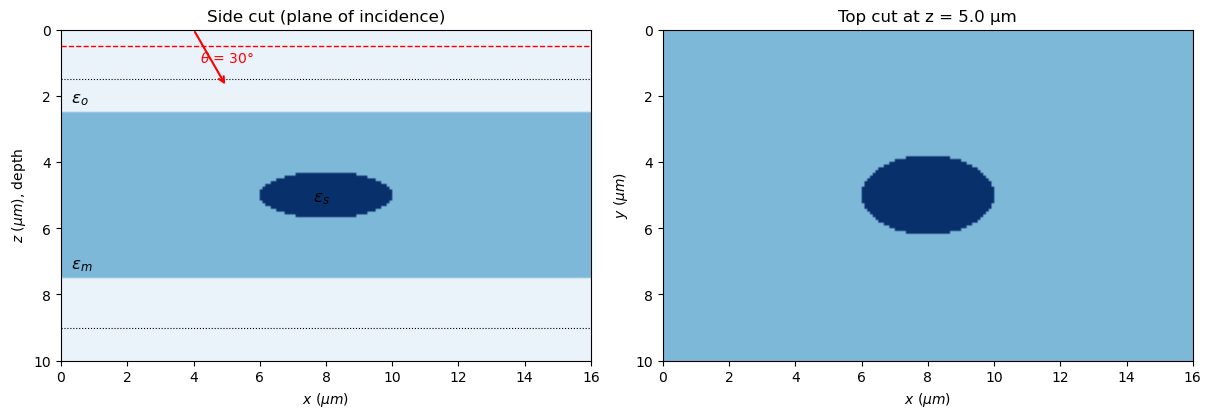

In [4]:
iy_c = int(center[1] / pixel_size)
iz_c = int(center[2] / pixel_size)
extent_xz = [0, sim_size[0], sim_size[2], 0]
extent_xy = [0, sim_size[0], sim_size[1], 0]

fig, (ax_s, ax_t) = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True,
                                 gridspec_kw={"width_ratios": [1, 1]})
ax_s.imshow(eps_sample[:, iy_c, :].real.T, cmap="Blues", extent=extent_xz, vmin=0.8, vmax=eps_s)
ax_s.axhline(z_src, color="red", ls="--", lw=1)
ax_s.axhline(z_up, color="k", ls=":", lw=0.8)
ax_s.axhline(z_down, color="k", ls=":", lw=0.8)
ax_s.annotate("", xy=(4 + 2 * np.sin(theta), 2 * np.cos(theta)), xytext=(4, 0),
              arrowprops=dict(arrowstyle="->", color="red", lw=1.5))
ax_s.text(4.2, 1.0, r"$\theta$ = %g°" % theta_deg, color="red")
ax_s.text(0.3, z_slab0 - 0.3, r"$\varepsilon_o$", fontsize=12)
ax_s.text(0.3, z_slab1 - 0.3, r"$\varepsilon_m$", fontsize=12)
ax_s.text(center[0] - 0.4, center[2] + 0.2, r"$\varepsilon_s$", fontsize=12)
ax_s.set_xlabel(r"$x~(\mu m)$")
ax_s.set_ylabel(r"$z~(\mu m)$, depth")
ax_s.set_title("Side cut (plane of incidence)")
ax_t.imshow(eps_sample[:, :, iz_c].real.T, cmap="Blues", extent=extent_xy, vmin=0.8, vmax=eps_s)
ax_t.set_xlabel(r"$x~(\mu m)$")
ax_t.set_ylabel(r"$y~(\mu m)$")
ax_t.set_title(f"Top cut at z = {center[2]} μm")
fig.savefig(f"{OUTPUT_DIR}/buried_ellipsoid_setup.png", dpi=200)

### Sources
One tilted sheet per polarization, at z_src, tapered at its edges. TE drives the current
along y, TM along x. A current along x launches a wave whose field is the part of x
transverse to the tilted direction, cos θ of it, so the TM sheet is scaled by 1 / cos θ
to give both polarizations the same incident amplitude.

In [5]:
def make_source(pol):
    axis = {"TE": 1, "TM": 0}[pol]
    values, position = plane_wave(shape=(sim_size[0], sim_size[1]), origin="topleft",
                                  position=(axis, 0.0, 0.0, z_src), source_plane="xy",
                                  pixel_size=pixel_size, theta=theta, wavelength=wavelength)
    if pol == "TM":
        values = values / np.cos(theta)
    return apodise((values, position), axes="xy", alpha=taper)


sources = {pol: make_source(pol) for pol in ("TE", "TM")}
for pol, (values, position) in sources.items():
    print(f"{pol}: source {values.shape} at voxel {tuple(int(p) for p in position)}, "
          f"polarization axis {'xyz'[position[0]]}, "
          f"|amplitude| max {np.abs(values).max():.3f}")

TE: source (1, 192, 120, 1) at voxel (1, 0, 0, 6), polarization axis y, |amplitude| max 1.000
TM: source (1, 192, 120, 1) at voxel (0, 0, 0, 6), polarization axis x, |amplitude| max 1.155


### Solve
Four solves: sample and reference for each polarization. The scattered field is their
difference. The reference field on two planes above the slab also gives the amplitude of
the incident wave, separated from the slab's reflection, as a check that both
polarizations arrive with the same amplitude.

Each solve returns five monitors, one voxel thick and the full domain across: the side
cut through the ellipsoid centre (y), the top cut at its depth (z), the two planes above
the slab for the incident amplitude and the plane below it.

In [6]:
iz_up, iz_up2, iz_down = int(z_up / pixel_size), int((z_up + 0.5) / pixel_size), int(z_down / pixel_size)


def plane_monitor(name, axis, index):
    """The voxel layer ``index`` along ``axis``, over the whole domain. The monitor box is
    half a voxel thick around the layer's centre, so it holds that layer alone; voxel i on
    an n-voxel axis sits at (i + 0.5 - n/2) * pixel_size in domain-centred coordinates."""
    a = "xyz".index(axis)
    centre, extent = [0.0, 0.0, 0.0], list(size)
    centre[a] = (index + 0.5 - (nx, ny, nz)[a] / 2) * pixel_size
    extent[a] = pixel_size / 2
    return create_monitor(name=name, center_x=centre[0], center_y=centre[1], center_z=centre[2],
                          size_x=extent[0], size_y=extent[1], size_z=extent[2])


monitors = [plane_monitor("side", "y", iy_c), plane_monitor("top", "z", iz_c),
            plane_monitor("up", "z", iz_up), plane_monitor("up2", "z", iz_up2),
            plane_monitor("down", "z", iz_down)]


def make_setup(case, pol):
    """The "sample" or the "reference" with the ``pol`` source and the monitors, in air."""
    setup = Setup(wavelength, pixel_size, (nx, ny, nz), boundary_width=boundary_width,
                  name=f"{NAME} {pol} {case}", folder=NAME)
    return setup.add(*shapes[case], sources[pol], *monitors)


def solve(case, pol):
    """One solve, filed in the folder NAME; returns the monitored planes as (3, n1, n2)
    arrays, keyed by monitor name."""
    start = time()
    run = submit(make_setup(case, pol)).wait()
    print(f"  {time() - start:.1f} s, {run.iterations} iterations, residual {run.residual_norm}")
    return {m["Name"]: u.reshape(3, *[s for s in u.shape[1:] if s != 1])
            for m, u in zip(monitors, run.get_monitors())}


def incident_amplitude(planes):
    """|E| of the down-going plane wave, from its Fourier component on two planes above the slab."""
    kz = k0 * np.cos(theta)
    ikx = int(round(np.sin(theta) * sim_size[0] / wavelength))    # Fourier bin of k0 sin(theta)
    e = np.stack([np.fft.fft2(planes[name], axes=(1, 2))[:, ikx, 0] for name in ("up", "up2")])
    m = np.array([[np.exp(1j * kz * z[i]), np.exp(-1j * kz * z[i])] for i in (iz_up, iz_up2)])   # down, up
    down, _ = np.linalg.solve(m, e)
    return np.linalg.norm(down)


scattered, incident = {}, {}
for pol in ("TE", "TM"):
    print(f"{pol}: sample run")
    u_sample = solve("sample", pol)
    print(f"{pol}: reference run")
    u_reference = solve("reference", pol)
    scattered[pol] = {name: u_sample[name] - u_reference[name] for name in u_sample}
    incident[pol] = incident_amplitude(u_reference)
    np.savez(f"{OUTPUT_DIR}/buried_ellipsoid_scattered_{pol}.npz", **scattered[pol])
print(f"Incident amplitude TE {incident['TE']:.4g}, TM {incident['TM']:.4g}, "
      f"ratio {incident['TE'] / incident['TM']:.3f} (1 = equal)")

TE: sample run

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 728f29d3-94e6-480a-a485-07481e5fcc24
  Version   : cbc5ee5a-50b2-4b94-9eb3-252523f82033
  Command   : 5909ea1b-1e23-4bca-9d56-9e6e54e7d4ca
  Mode      : Maxwell (vectorial)
  Domain    : 192x120x120 voxels  lambda=1.0 um  dx=0.083 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  31.7 s, 261 iterations, residual 9.293547e-07
TE: reference run

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 0f18539e-bfc5-49ce-beae-5a1bf1ef67c5
  Version   : 3e586882-7925-494e-a688-2b603a92b169
  Command   : e67aae0c-1e01-4d24-8113-7193addcc2f2
  Mode      : Maxwell (vectorial)
  Domain    : 192x120x120 voxels  lambda=1.0 um  dx=0.083


Primitives 'slab' (n=(1.5+0j)) and 'ellipsoid' (n=(2+0j)) may overlap (bounding boxes intersect). Where they do, 'ellipsoid' wins because it comes later in the list (painter's rule); materials are never blended.


TM: sample run

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 83ff5104-b22a-4f37-9a30-c89b3575520f
  Version   : 5fbc1b3d-c3fd-4102-8745-6d8f47700d17
  Command   : c68c8195-45b9-4fd0-8dbb-b22e57bec4b1
  Mode      : Maxwell (vectorial)
  Domain    : 192x120x120 voxels  lambda=1.0 um  dx=0.083 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  42.9 s, 238 iterations, residual 9.109355e-07
TM: reference run

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 5b9d7abf-bebd-4746-9923-5e8946a08fdc
  Version   : d84526cb-7df6-4760-8a70-f50c4778d135
  Command   : 7f7be1a2-6bf5-4ead-b109-191662b9e862
  Mode      : Maxwell (vectorial)
  Domain    : 192x120x120 voxels  lambda=1.0 um  dx=0.083

### Figure 1: scattered field
|E_scattered| on the same side and top cuts, one row per polarization, one colour scale
for all four panels.

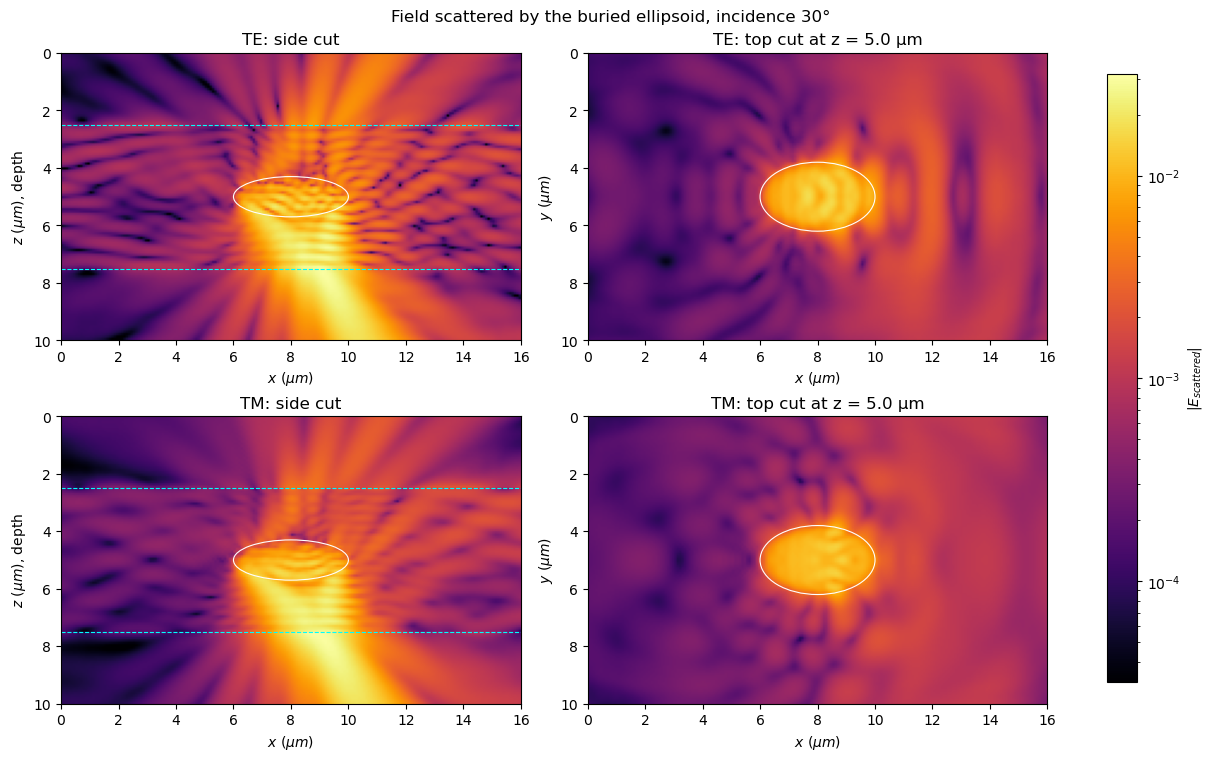

In [7]:
amp = {pol: {cut: np.sqrt(np.sum(np.abs(u[cut]) ** 2, axis=0)) for cut in ("side", "top")}
       for pol, u in scattered.items()}
vmax = max(a[cut].max() for a in amp.values() for cut in a)
norm = colors.LogNorm(vmin=vmax * 1e-3, vmax=vmax)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), constrained_layout=True)
for row, pol in zip(axes, ("TE", "TM")):
    im = row[0].imshow(amp[pol]["side"].T, cmap="inferno", extent=extent_xz, norm=norm)
    row[0].axhline(z_slab0, color="cyan", ls="--", lw=0.8)
    row[0].axhline(z_slab1, color="cyan", ls="--", lw=0.8)
    row[0].add_patch(Ellipse((center[0], center[2]), 2 * semi_axes[0], 2 * semi_axes[2],
                             fill=False, ec="white", lw=0.8))
    row[0].set_title(f"{pol}: side cut")
    row[0].set_xlabel(r"$x~(\mu m)$")
    row[0].set_ylabel(r"$z~(\mu m)$, depth")
    row[1].imshow(amp[pol]["top"].T, cmap="inferno", extent=extent_xy, norm=norm)
    row[1].add_patch(Ellipse((center[0], center[1]), 2 * semi_axes[0], 2 * semi_axes[1],
                             fill=False, ec="white", lw=0.8))
    row[1].set_title(f"{pol}: top cut at z = {center[2]} μm")
    row[1].set_xlabel(r"$x~(\mu m)$")
    row[1].set_ylabel(r"$y~(\mu m)$")
fig.colorbar(im, ax=axes, fraction=0.03).set_label(r"$|E_{scattered}|$")
fig.suptitle(f"Field scattered by the buried ellipsoid, incidence {theta_deg:.0f}°")
fig.savefig(f"{OUTPUT_DIR}/buried_ellipsoid_field.png", dpi=200)

### Figure 2: angular spectrum of the back-scattered light
The scattered field on the plane z_up, between the source and the slab, Fourier
transformed along x and y: intensity against the direction cosines (sin θ_x, sin θ_y) of
the waves travelling up into the air. The cross marks the specular direction of the
incident wave for orientation; the slab's own specular reflection is not in this field,
only what the inclusion scatters. Below it, the scattered power leaving up and down.


Scattered power on the read planes, |E|^2 summed over the plane (arb. units)
             up       down  up/down
TE    1.732e-02  1.898e-01    0.091
TM    8.902e-03  2.027e-01    0.044
Saved output/mx_buried_ellipsoid/buried_ellipsoid_setup.png, _field.png, _angular.png


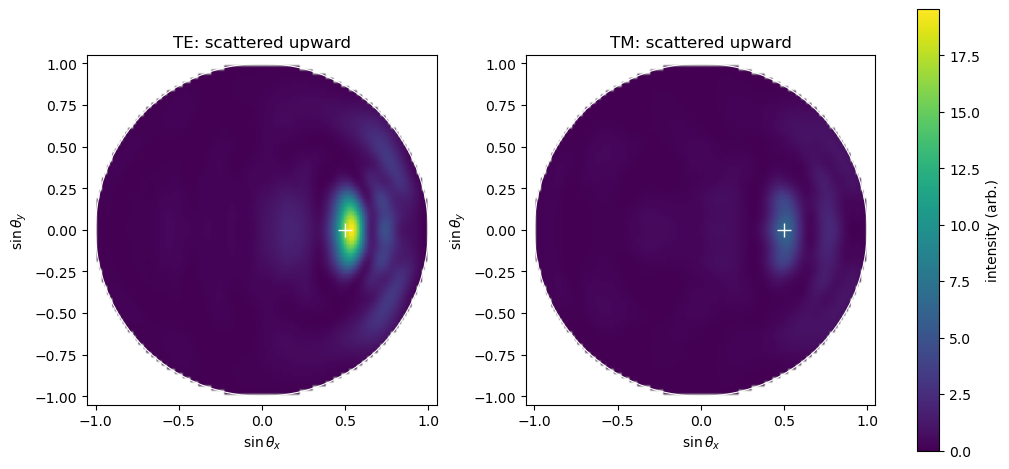

In [8]:
pad = 4                                       # zero-padding factor for a smoother spectrum
kx = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(pad * nx, pixel_size)) / k0
ky = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(pad * ny, pixel_size)) / k0
propagating = (kx[:, None] ** 2 + ky[None, :] ** 2) < 1


def angular_spectrum(u_plane):
    spectrum = np.fft.fftshift(np.fft.fft2(u_plane, s=(pad * nx, pad * ny), axes=(1, 2)), axes=(1, 2))
    return np.where(propagating, np.sum(np.abs(spectrum) ** 2, axis=0), np.nan)


spectra = {pol: angular_spectrum(u["up"]) for pol, u in scattered.items()}
smax = max(np.nanmax(s) for s in spectra.values())
extent_k = [kx[0], kx[-1], ky[-1], ky[0]]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True)
for ax, pol in zip(axes, ("TE", "TM")):
    im = ax.imshow(spectra[pol].T, cmap="viridis", extent=extent_k, vmin=0, vmax=smax)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ec="white", lw=0.8))
    ax.plot(np.sin(theta), 0, "w+", ms=10)
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel(r"$\sin\theta_x$")
    ax.set_ylabel(r"$\sin\theta_y$")
    ax.set_title(f"{pol}: scattered upward")
fig.colorbar(im, ax=axes, fraction=0.03).set_label("intensity (arb.)")
fig.savefig(f"{OUTPUT_DIR}/buried_ellipsoid_angular.png", dpi=200)

print("\nScattered power on the read planes, |E|^2 summed over the plane (arb. units)")
print(f"{'':4s} {'up':>10s} {'down':>10s} {'up/down':>8s}")
for pol, u in scattered.items():
    p_up = float(np.sum(np.abs(u["up"]) ** 2))
    p_down = float(np.sum(np.abs(u["down"]) ** 2))
    print(f"{pol:4s} {p_up:10.3e} {p_down:10.3e} {p_up / p_down:8.3f}")
print(f"Saved output/{NAME}/buried_ellipsoid_setup.png, _field.png, _angular.png")

plt.show()